# Project Overview
Credit card fraud is a major financial challenge that can lead to significant losses for banks and customers. The objective of this project is to identify fraudulent transactions by detecting unusual patterns and anomalies in transaction data. The project focuses on data analysis, preprocessing, feature engineering, and visualization to understand transaction behavior. Anomaly detection techniques such as Isolation Forest and Local Outlier Factor (LOF) are used to identify suspicious transactions that deviate from normal patterns. The system aims to detect previously unseen fraud patterns and provide early insights into potentially fraudulent activities

# Step 1: Load Important Modules

In [1]:
# Standard library
import warnings
from pathlib import Path

# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_recall_curve, confusion_matrix,
    precision_score, recall_score, f1_score,
)

# Imbalance handling (used only for the supervised baseline)
import imblearn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Saving the trained model
import joblib

# Global settings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

RANDOM_STATE = 42

# Project folders (works whether the notebook is run from notebooks/ or the repo root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("All imports OK")
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("imblearn    :", imblearn.__version__)

All imports OK
pandas      : 3.1.0
scikit-learn: 1.9.1
imblearn    : 0.14.2


# Step 2: Load Data

In [2]:
# Local copy (git lfs pull); falls back to the GitHub raw file, e.g. when running on Colab
DATA_PATH = ROOT / "data" / "creditcard.csv"
DATA_URL = "https://github.com/Parthik73/Credit-Card-Fraud-Detection-Using-Anomaly-Detection-Techniques/raw/refs/heads/main/data/creditcard.csv"
df = pd.read_csv(DATA_PATH if DATA_PATH.exists() else DATA_URL)
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")

Rows: 284,807   Columns: 31

# Step 3: EDA(Exploratory Data Analysis)

In [3]:
# Step 3.1: Show df data sample
df.sample(5, random_state=42)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
43428,41505.0,-16.526507,8.584972,-18.649853,9.505594,-13.793819,-2.832404,-16.701694,7.517344,-8.507059,-14.110184,5.299236,-10.834006,1.671120,-9.373859,0.360806,-9.899247,-19.236292,-8.398552,3.101735,-1.514923,1.190739,-1.127670,-2.358579,0.673461,-1.413700,-0.462762,-2.018575,-1.042804,364.19,1
49906,44261.0,0.339812,-2.743745,-0.134070,-1.385729,-1.451413,1.015887,-0.524379,0.224060,0.899746,-0.565012,-0.087670,0.979427,0.076883,-0.217884,-0.136830,-2.142892,0.126956,1.752662,0.432546,0.506044,-0.213436,-0.942525,-0.526819,-1.156992,0.311211,-0.746647,0.040996,0.102038,520.12,0
29474,35484.0,1.399590,-0.590701,0.168619,-1.029950,-0.539806,0.040444,-0.712567,0.002299,-0.971747,0.756801,0.543827,0.112453,1.075384,-0.245772,0.180483,1.769860,-0.533172,-0.533300,1.192245,0.212877,0.102398,0.168269,-0.166639,-0.810250,0.505083,-0.232340,0.011409,0.004634,31.00,0
276481,167123.0,-0.432071,1.647895,-1.669361,-0.349504,0.785785,-0.630647,0.276990,0.586025,-0.484715,-1.376648,-1.328335,0.223621,1.132627,-0.550875,0.616568,0.497974,0.502195,0.981343,0.101264,-0.244633,0.358932,0.873663,-0.178642,-0.017171,-0.207392,-0.157756,-0.237386,0.001934,1.50,0
278846,168473.0,2.014160,-0.137394,-1.015839,0.327269,-0.182179,-0.956571,0.043241,-0.160746,0.363241,0.259452,0.942162,0.850038,-0.616166,0.592634,-0.603845,0.091077,-0.471867,-0.333816,0.404711,-0.255293,-0.238644,-0.616400,0.347045,0.061561,-0.360196,0.174730,-0.078043,-0.070571,0.89,0


In [4]:
# Step 3.2: Show df shape and size
print("df shape :- ", df.shape)
print("df size :- ", df.size)

df shape :-  (284807, 31)
df size :-  8829017


In [5]:
# Step 3.3: Show column info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [6]:
# Step 3.4: Check missing values
print("Total missing values :- ", df.isnull().sum().sum())
df.isnull().sum().sort_values(ascending=False).head()
# isnull(): marks missing cells as True, sum(): counts them per column

Total missing values :-  0


Time    0
V1      0
V2      0
V3      0
V4      0
dtype: int64

In [7]:
# Step 3.5: Check duplicate rows
dup_count = df.duplicated().sum()
print("Duplicate rows :- ", dup_count)
print("Duplicate share :- ", f"{dup_count / len(df):.2%}")
print("Fraud rows among duplicates :- ", df[df.duplicated()]["Class"].sum())

Duplicate rows :-  1081
Duplicate share :-  0.38%


Fraud rows among duplicates :-  19


In [8]:
# Step 3.6: Divide columns into required objects
target_column = "Class"
original_columns = ["Time", "Amount"]
pca_columns = [c for c in df.columns if c.startswith("V")]

print("Target Column :- ", target_column)
print("="*100)
print("Original Columns :- ", original_columns)
print("="*100)
print("PCA Columns :- ", len(pca_columns), "->", pca_columns[0], "to", pca_columns[-1])
# V1-V28 are anonymised PCA components; only Time and Amount are the real columns

Target Column :-  Class
Original Columns :-  ['Time', 'Amount']
PCA Columns :-  28 -> V1 to V28


In [9]:
# Step 3.7: Show stats of Time and Amount
df[original_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16


In [10]:
# Step 3.8: Show stats of PCA features
df[pca_columns].describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
V1,0.0,1.96,-56.41,2.45
V2,0.0,1.65,-72.72,22.06
V3,-0.0,1.52,-48.33,9.38
V4,0.0,1.42,-5.68,16.88
V5,0.0,1.38,-113.74,34.80
V6,0.0,1.33,-26.16,73.30
V7,-0.0,1.24,-43.56,120.59
V8,0.0,1.19,-73.22,20.01
V9,-0.0,1.10,-13.43,15.59
V10,0.0,1.09,-24.59,23.75


,Count,Percent
Legitimate (0),284315,99.827
Fraud (1),492,0.173



1 fraud for every 578 legitimate transactions


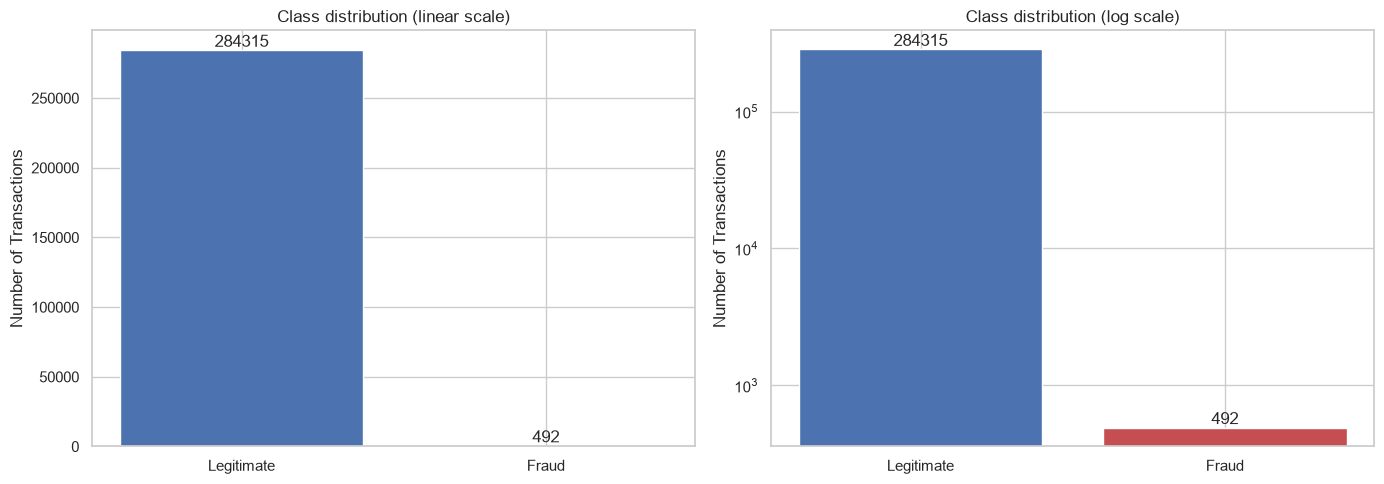

In [11]:
# Step 3.9: Show target (Class) distribution
counts = df["Class"].value_counts().sort_index()
percent = (df["Class"].value_counts(normalize=True).sort_index() * 100).round(3)

class_summary = pd.DataFrame({"Count": counts, "Percent": percent})
class_summary.index = ["Legitimate (0)", "Fraud (1)"]
display(class_summary)

print(f"\n1 fraud for every {counts[0] / counts[1]:.0f} legitimate transactions")

plt.figure(figsize=(14,5))
for i, scale in enumerate(["linear", "log"]):
    plt.subplot(1,2,i+1)
    plt.title(f"Class distribution ({scale} scale)")
    ax = plt.bar(["Legitimate", "Fraud"], counts.values, color=["#4C72B0", "#C44E52"])
    plt.bar_label(ax)
    plt.yscale(scale)
    plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

# log scale is used because fraud bar is invisible on the normal scale

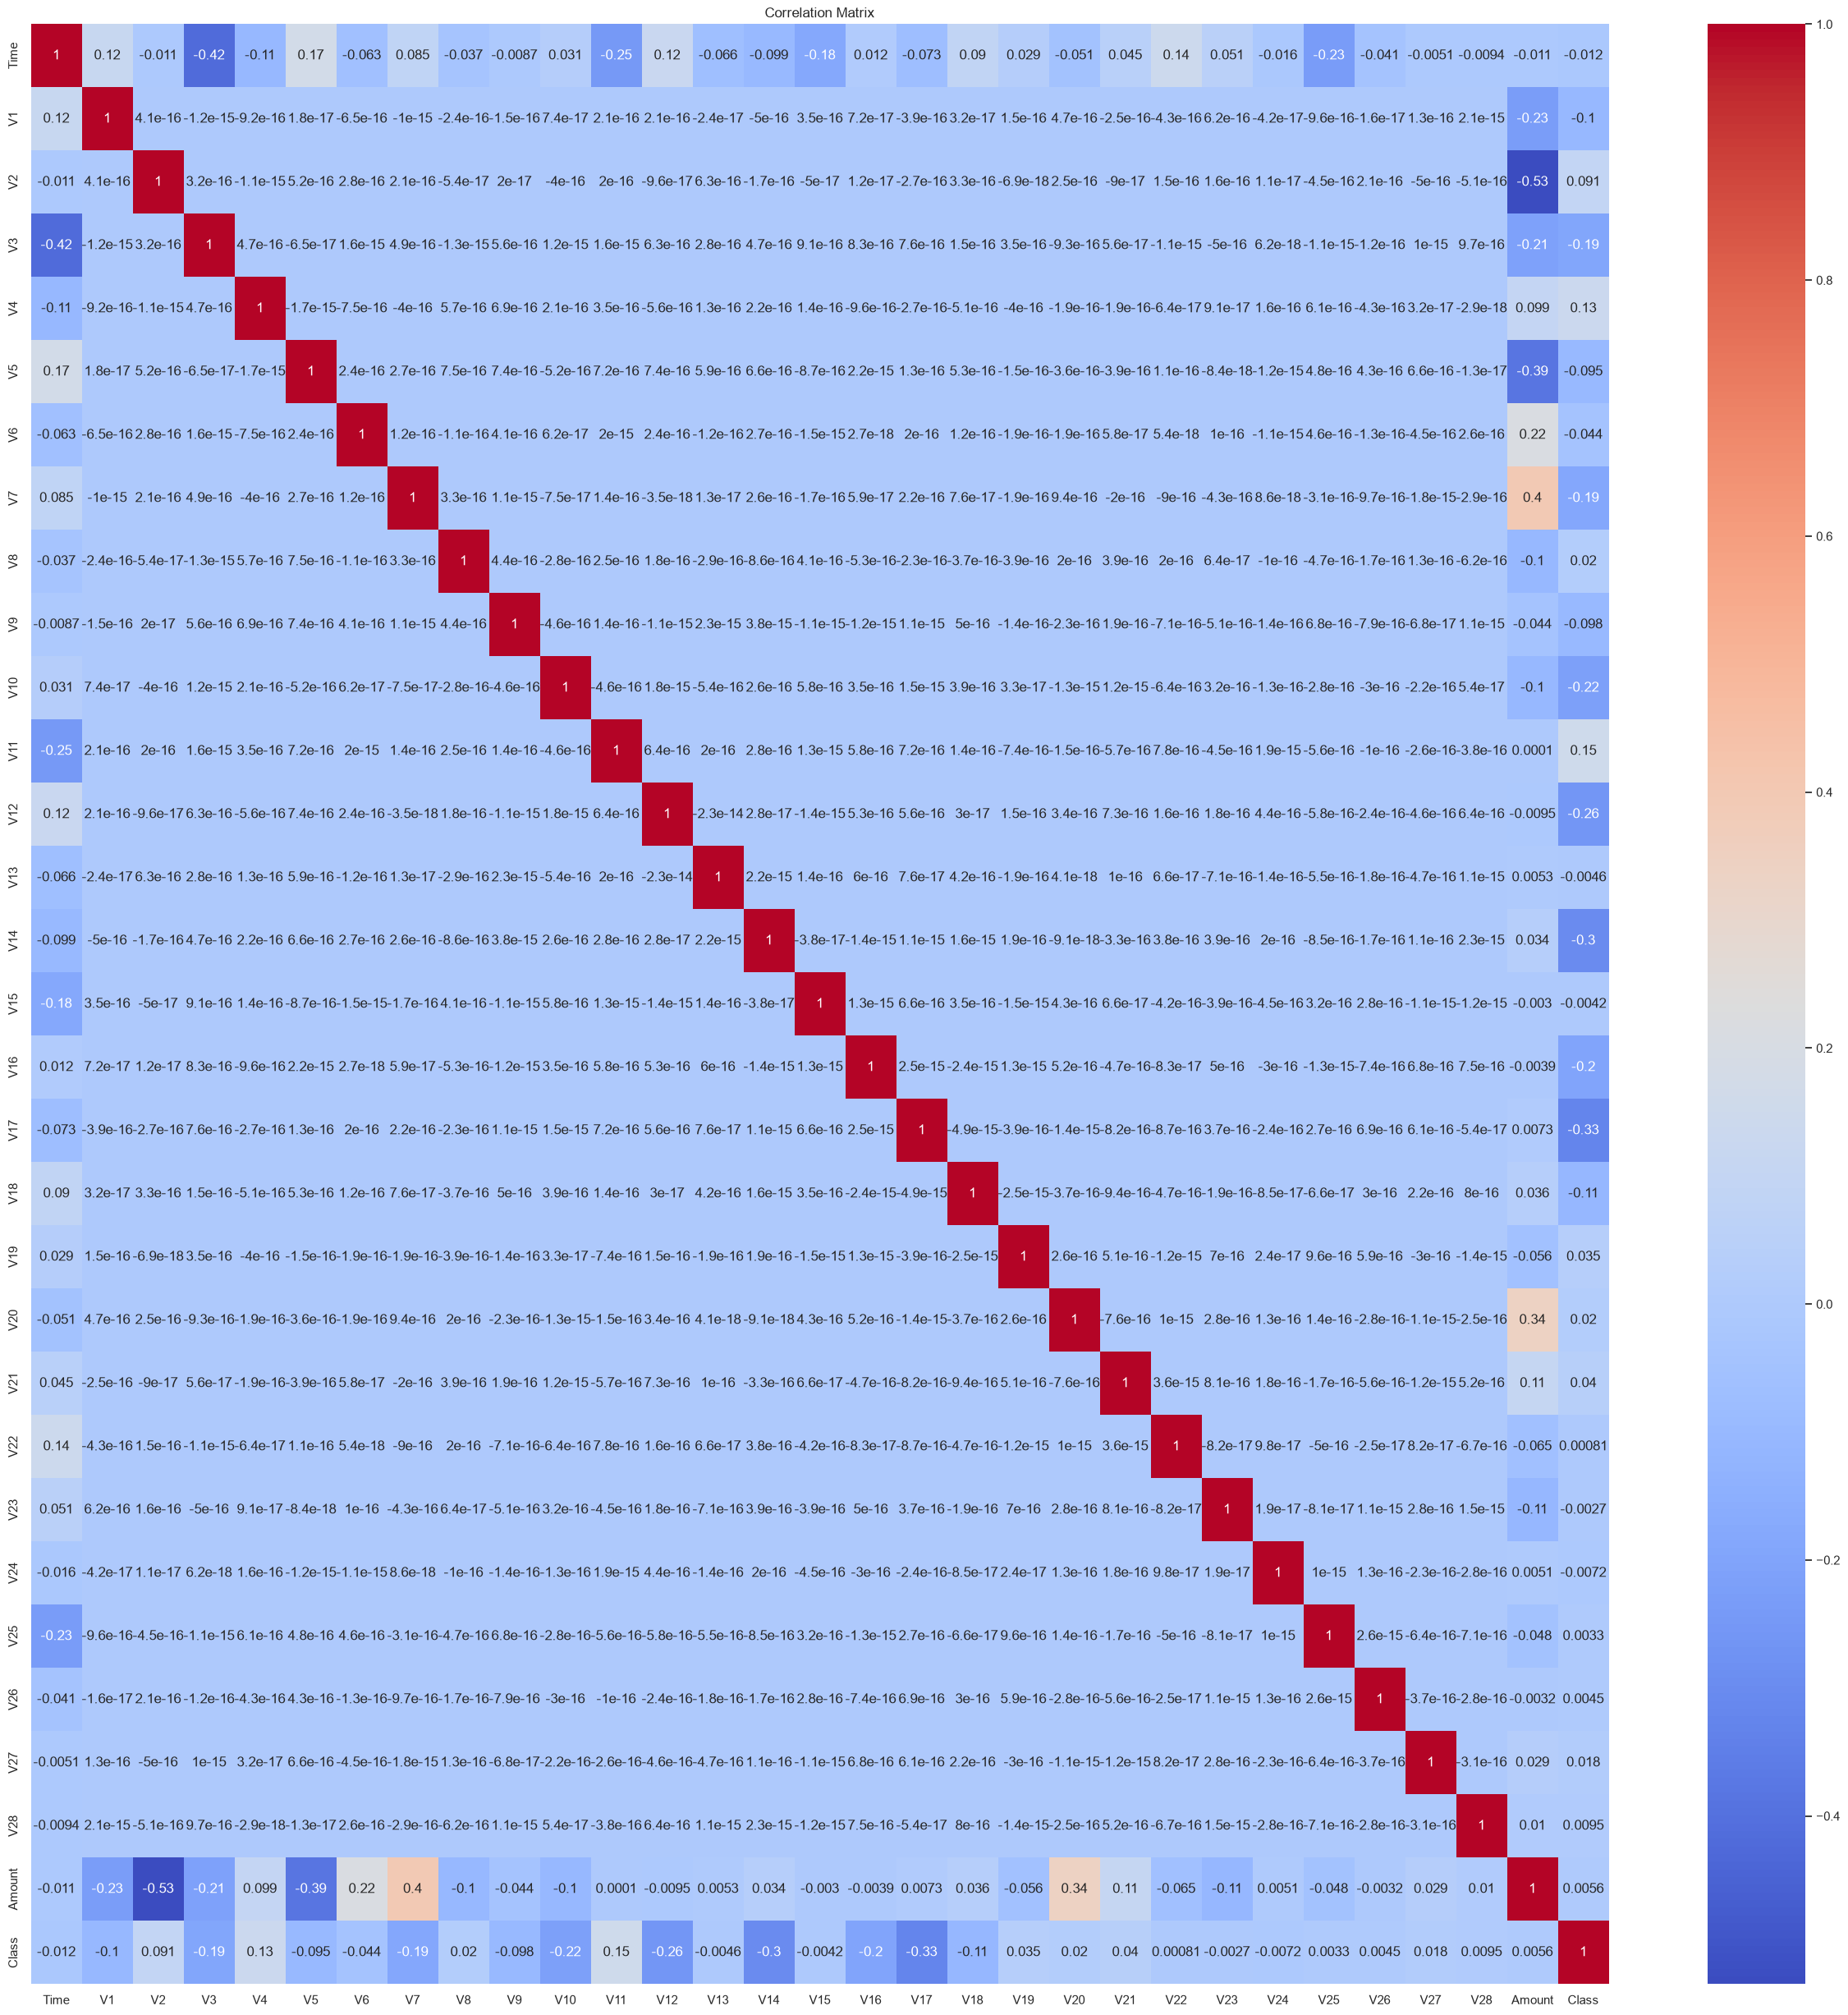

In [12]:
# Step 3.10: Show Correlation Matrix
plt.figure(figsize=(31,31))
plt.title("Correlation Matrix")
sns.heatmap(df.corr(), cmap="coolwarm",annot=True)
plt.show()

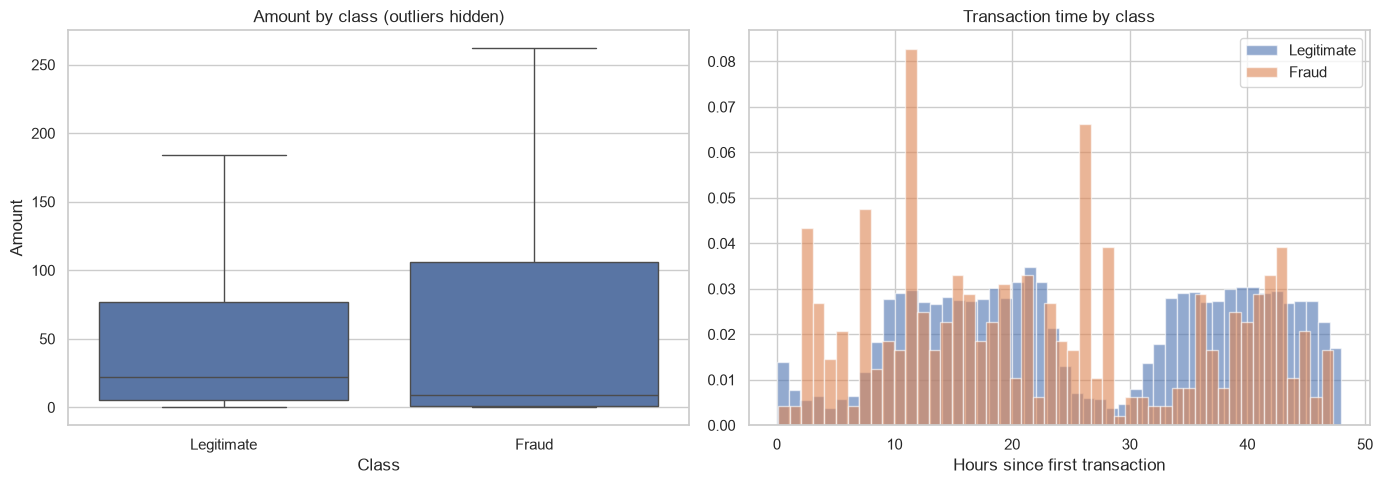

In [13]:
# Step 3.11: Compare transaction amounts of legitimate vs fraud transactions
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.boxplot(x="Class", y="Amount", data=df, showfliers=False)
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Amount by class (outliers hidden)")
plt.subplot(1, 2, 2)
plt.hist(df.loc[df["Class"] == 0, "Time"] / 3600, bins=48, alpha=0.6, density=True, label="Legitimate")
plt.hist(df.loc[df["Class"] == 1, "Time"] / 3600, bins=48, alpha=0.6, density=True, label="Fraud")
plt.xlabel("Hours since first transaction")
plt.title("Transaction time by class")
plt.legend()
plt.tight_layout()
plt.show()
# Fraud is spread more evenly over the night hours, when legitimate traffic drops

# Step 4: Data Cleaning
Rows with missing values and exact duplicates are removed. Duplicates would otherwise leak between the train and test splits.

In [14]:
# Step 4.1: Drop missing values and duplicate rows
FEATURES = ["Time", *pca_columns, "Amount"]
TARGET = target_column

data = df[FEATURES + [TARGET]].copy()
data[TARGET] = pd.to_numeric(data[TARGET], errors="coerce")
rows_raw = len(data)

data = data.dropna()
missing_removed = rows_raw - len(data)
rows_before_dedupe = len(data)
data = data.drop_duplicates().reset_index(drop=True)
duplicates_removed = rows_before_dedupe - len(data)
data[TARGET] = data[TARGET].astype(int)

dataset_summary = {
    "rows_raw": int(rows_raw),
    "rows_with_missing_removed": int(missing_removed),
    "duplicates_removed": int(duplicates_removed),
    "rows_clean": int(len(data)),
    "frauds": int(data[TARGET].sum()),
    "fraud_rate": float(data[TARGET].mean()),
}
pd.Series(dataset_summary)

rows_raw                     284807.000000
rows_with_missing_removed         0.000000
duplicates_removed             1081.000000
rows_clean                   283726.000000
frauds                          473.000000
fraud_rate                        0.001667
dtype: float64

In [15]:
# Step 4.2: Data dictionary (every column described)
descriptions = {
    "Time": "Seconds elapsed between this transaction and the first transaction in the dataset",
    "Amount": "Transaction amount (EUR)",
    "Class": "Target label: 1 = fraudulent transaction, 0 = legitimate transaction",
}
data_dictionary = pd.DataFrame([
    {
        "column": col,
        "dtype": str(data[col].dtype),
        "description": descriptions.get(col, f"Anonymised principal component {col} (PCA-transformed by the data provider)"),
        "role": "target" if col == TARGET else "feature",
        "min": round(float(data[col].min()), 4),
        "max": round(float(data[col].max()), 4),
        "mean": round(float(data[col].mean()), 4),
        "missing": int(data[col].isna().sum()),
    }
    for col in data.columns
])
data_dictionary.head(8)

,column,dtype,description,role,min,max,mean,missing
0,Time,float64,Seconds elapsed between this transaction and t...,feature,0.0000,172792.0000,94811.0776,0
1,V1,float64,Anonymised principal component V1 (PCA-transfo...,feature,-56.4075,2.4549,0.0059,0
2,V2,float64,Anonymised principal component V2 (PCA-transfo...,feature,-72.7157,22.0577,-0.0041,0
3,V3,float64,Anonymised principal component V3 (PCA-transfo...,feature,-48.3256,9.3826,0.0016,0
4,V4,float64,Anonymised principal component V4 (PCA-transfo...,feature,-5.6832,16.8753,-0.0030,0
5,V5,float64,Anonymised principal component V5 (PCA-transfo...,feature,-113.7433,34.8017,0.0018,0
6,V6,float64,Anonymised principal component V6 (PCA-transfo...,feature,-26.1605,73.3016,-0.0011,0
7,V7,float64,Anonymised principal component V7 (PCA-transfo...,feature,-43.5572,120.5895,0.0018,0


In [16]:
# Step 4.3: Cleaning stays in memory. data/ keeps only creditcard.csv
print(f"Cleaned rows: {len(data):,}")

Saved 283,726 cleaned rows


# Step 5: Train / Validation / Test Split and Scaling
- **train** (60%): fits the scaler and the anomaly detectors. The detectors never see the labels.
- **validation** (20%): tunes each model's decision threshold.
- **test** (20%): final, untouched evaluation.

`V1`-`V28` are already PCA outputs. Only `Time` and `Amount` are scaled. A `RobustScaler` (median / IQR) is used because `Amount` is heavily skewed with large outliers. It is fitted on the training split only.

In [17]:
# Step 5.1: Stratified split (keeps the 0.17% fraud rate in every part)
train_val, test = train_test_split(data, test_size=0.2, stratify=data[TARGET], random_state=RANDOM_STATE)
train, val = train_test_split(train_val, test_size=0.25, stratify=train_val[TARGET], random_state=RANDOM_STATE)

pd.DataFrame({
    name: {"rows": len(part), "frauds": int(part[TARGET].sum()), "fraud_rate_%": round(part[TARGET].mean() * 100, 3)}
    for name, part in [("train", train), ("validation", val), ("test", test)]
}).T

,rows,frauds,fraud_rate_%
train,170235.0,284.0,0.167
validation,56745.0,94.0,0.166
test,56746.0,95.0,0.167


In [18]:
# Step 5.2: Scale Time and Amount
SCALED_FEATURES = ["Time", "Amount"]
scaler = RobustScaler().fit(train[SCALED_FEATURES])

def prepare(part):
    X = part[FEATURES].copy()
    X[SCALED_FEATURES] = scaler.transform(X[SCALED_FEATURES])
    return X

X_train, X_val, X_test = prepare(train), prepare(val), prepare(test)
y_train, y_val, y_test = train[TARGET].to_numpy(), val[TARGET].to_numpy(), test[TARGET].to_numpy()
X_train[SCALED_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
Time,170235.0,0.117117,0.558089,-0.997991,-0.361328,0.0,0.638672,1.031561
Amount,170235.0,0.919683,3.427915,-0.306558,-0.227554,0.0,0.772446,273.099520


# Step 6: Anomaly Detection Models
Both models are **unsupervised**: they learn what normal traffic looks like without using the `Class` labels.

- **Isolation Forest** isolates points with random splits. Anomalies need fewer splits to isolate.
- **Local Outlier Factor** compares each point's local density with its neighbours'. `novelty=True` lets the fitted model score new transactions. It is fitted on a 20,000-row sample to keep training and prediction fast.

The anomaly score is `-score_samples(X)`: higher means more anomalous. A transaction is flagged as fraud when its score is at or above a threshold. The threshold is chosen to maximise F1 on the **validation** split.

In [19]:
# Step 6.1: Helper functions for scoring, threshold tuning and evaluation
def anomaly_score(model, X):
    return -model.score_samples(X)

def best_f1_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[int(np.argmax(f1[:-1]))])

def evaluate(y_true, scores, threshold):
    y_pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "pr_auc": float(average_precision_score(y_true, scores)),
        "roc_auc": float(roc_auc_score(y_true, scores)),
        "false_positive_rate": float(fp / (fp + tn)),
        "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    }

results, test_scores = {}, {}

In [20]:
# Step 6.2: Isolation Forest (fitted on the full training split, labels unused)
iso_forest = IsolationForest(n_estimators=300, max_samples=2048, contamination="auto",
                             n_jobs=-1, random_state=RANDOM_STATE)
iso_forest.fit(X_train)

iso_threshold = best_f1_threshold(y_val, anomaly_score(iso_forest, X_val))
test_scores["isolation_forest"] = anomaly_score(iso_forest, X_test)
results["isolation_forest"] = evaluate(y_test, test_scores["isolation_forest"], iso_threshold)
pd.Series(results["isolation_forest"]).drop("confusion_matrix")

threshold              0.594537
precision               0.19171
recall                 0.389474
f1                     0.256944
pr_auc                 0.172417
roc_auc                0.937843
false_positive_rate    0.002754
dtype: object

In [21]:
# Step 6.3: Local Outlier Factor (novelty mode, fitted on a 20,000-row sample)
LOF_SAMPLE_SIZE = 20_000
X_lof = X_train.sample(n=min(LOF_SAMPLE_SIZE, len(X_train)), random_state=RANDOM_STATE)
lof = LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=-1)
lof.fit(X_lof)

lof_threshold = best_f1_threshold(y_val, anomaly_score(lof, X_val))
test_scores["lof"] = anomaly_score(lof, X_test)
results["lof"] = evaluate(y_test, test_scores["lof"], lof_threshold)
pd.Series(results["lof"]).drop("confusion_matrix")

threshold              2.460144
precision              0.346154
recall                 0.378947
f1                     0.361809
pr_auc                 0.215624
roc_auc                0.942479
false_positive_rate      0.0012
dtype: object

# Step 7: Supervised Baseline (SMOTE + Logistic Regression)
For comparison only. SMOTE creates synthetic fraud examples inside the training pipeline, so validation and test data are never oversampled. This model needs labels, while the anomaly detectors do not.

In [22]:
# Step 7.1: Train and evaluate the baseline
baseline = ImbPipeline([
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

baseline_threshold = best_f1_threshold(y_val, baseline.predict_proba(X_val)[:, 1])
test_scores["smote_logistic_regression"] = baseline.predict_proba(X_test)[:, 1]
results["smote_logistic_regression"] = evaluate(y_test, test_scores["smote_logistic_regression"], baseline_threshold)

# Step 8: Model Comparison (test set)
Accuracy is left out on purpose: always predicting "legitimate" already scores about 99.8%.

In [23]:
# Step 8.1: Metrics table
MODEL_NAMES = {
    "isolation_forest": "Isolation Forest",
    "lof": "Local Outlier Factor",
    "smote_logistic_regression": "SMOTE + Logistic Regression (baseline)",
}
comparison = pd.DataFrame({
    MODEL_NAMES[key]: {
        "precision": m["precision"], "recall": m["recall"], "f1": m["f1"],
        "pr_auc": m["pr_auc"], "roc_auc": m["roc_auc"],
        "frauds_caught": f"{m['confusion_matrix']['tp']}/{m['confusion_matrix']['tp'] + m['confusion_matrix']['fn']}",
        "false_alarms": m["confusion_matrix"]["fp"],
    }
    for key, m in results.items()
}).T
comparison

,precision,recall,f1,pr_auc,roc_auc,frauds_caught,false_alarms
Isolation Forest,0.19171,0.389474,0.256944,0.172417,0.937843,37/95,156
Local Outlier Factor,0.346154,0.378947,0.361809,0.215624,0.942479,36/95,68
SMOTE + Logistic Regression (baseline),0.884615,0.726316,0.797688,0.687869,0.95825,69/95,9


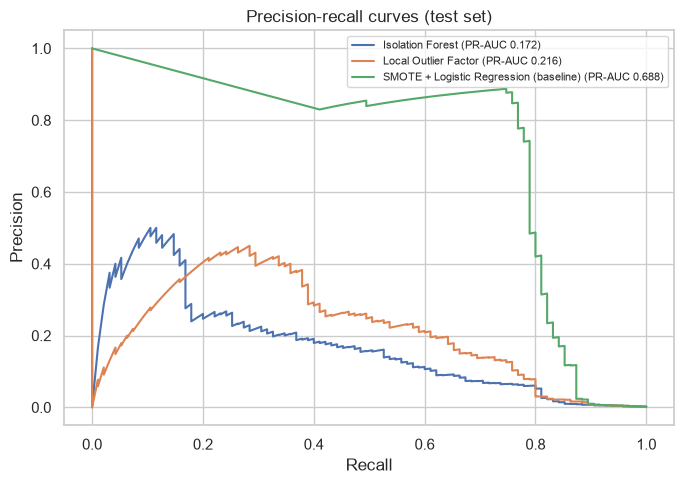

In [24]:
# Step 8.2: Precision-recall curves
plt.figure(figsize=(7, 5))
for key, scores in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    plt.plot(recall, precision, label=f"{MODEL_NAMES[key]} (PR-AUC {results[key]['pr_auc']:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curves (test set)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

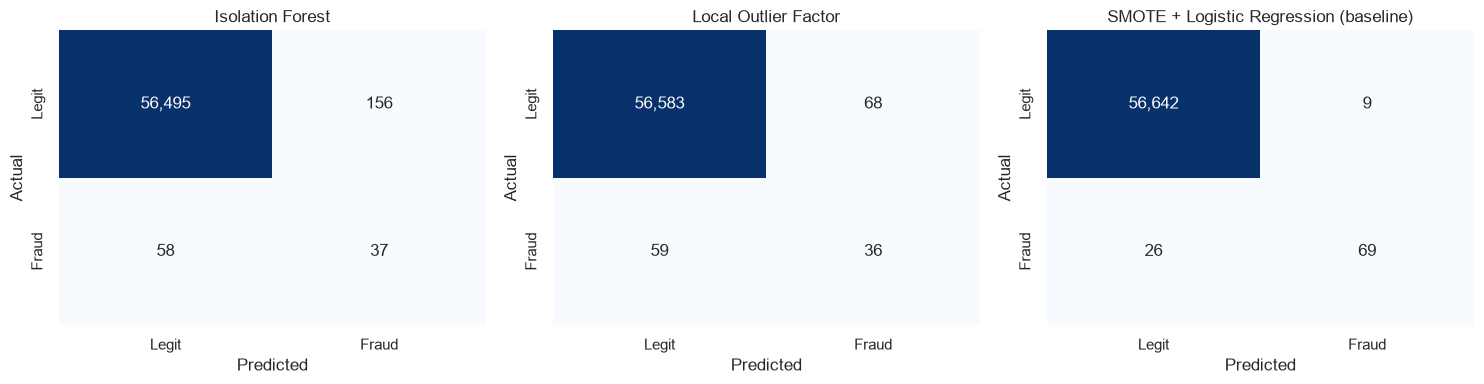

In [25]:
# Step 8.3: Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (key, m) in zip(axes, results.items()):
    cm = m["confusion_matrix"]
    sns.heatmap([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]], annot=True, fmt=",", cmap="Blues", cbar=False,
                xticklabels=["Legit", "Fraud"], yticklabels=["Legit", "Fraud"], ax=ax)
    ax.set_title(MODEL_NAMES[key])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

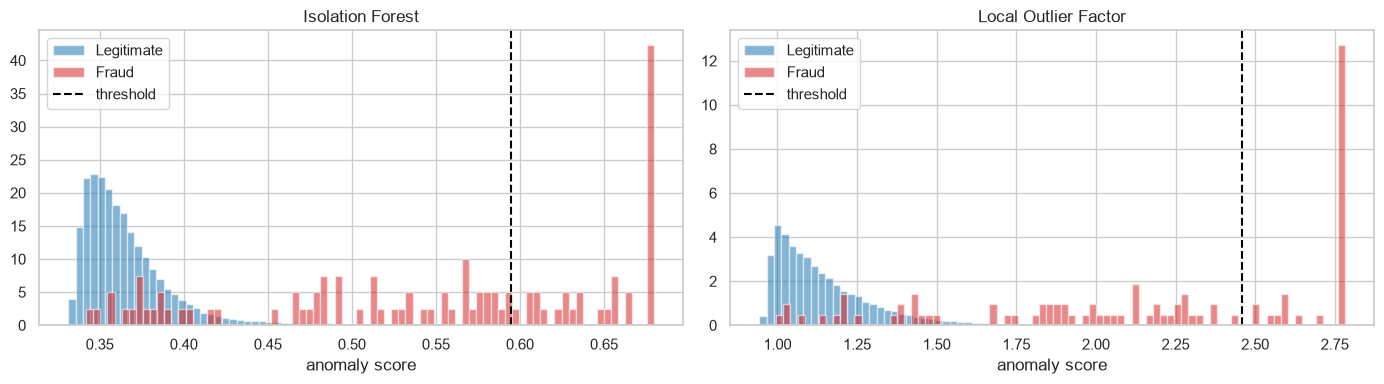

In [26]:
# Step 8.4: Anomaly score distributions (dashed line = tuned threshold)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, key in zip(axes, ["isolation_forest", "lof"]):
    scores = test_scores[key]
    upper = np.quantile(scores, 0.999)
    for label, color in [(0, "tab:blue"), (1, "tab:red")]:
        ax.hist(np.clip(scores[y_test == label], None, upper), bins=80, density=True, alpha=0.55,
                color=color, label="Fraud" if label else "Legitimate")
    ax.axvline(results[key]["threshold"], color="black", linestyle="--", label="threshold")
    ax.set_title(MODEL_NAMES[key])
    ax.set_xlabel("anomaly score")
    ax.legend()
plt.tight_layout()
plt.show()

# Step 9: Save the Model Artifacts
The app loads these two files. Isolation Forest is the deployed model. Its validation-tuned threshold is stored on the model as `fraud_threshold_`. Local Outlier Factor stays in this notebook for comparison.

| File | Content |
|---|---|
| `models/fraud_model.pkl` | fitted `IsolationForest` plus the tuned threshold |
| `models/scaler.pkl` | `RobustScaler` for `Time` and `Amount` |

In [27]:
# Step 9.1: Save the Isolation Forest and the scaler for app.py
iso_forest.fraud_threshold_ = float(iso_threshold)
joblib.dump(iso_forest, MODELS_DIR / "fraud_model.pkl")
joblib.dump(scaler, MODELS_DIR / "scaler.pkl")
print("Saved: models/fraud_model.pkl, models/scaler.pkl")
print(f"Isolation Forest threshold: {iso_forest.fraud_threshold_:.4f}")

Saved: models/fraud_model.pkl, models/scaler.pkl
Isolation Forest threshold: 0.5945


In [28]:
# Step 9.2: Reload the saved files and score a small test sample the same way app.py does
loaded_model = joblib.load(MODELS_DIR / "fraud_model.pkl")
loaded_scaler = joblib.load(MODELS_DIR / "scaler.pkl")

sample = pd.concat([
    test[test[TARGET] == 0].sample(40, random_state=RANDOM_STATE),
    test[test[TARGET] == 1].sample(10, random_state=RANDOM_STATE),
]).sample(frac=1, random_state=RANDOM_STATE)

X_sample = sample[FEATURES].copy()
X_sample[SCALED_FEATURES] = loaded_scaler.transform(X_sample[SCALED_FEATURES])
check = sample[[TARGET]].copy()
check["fraud_flag"] = (-loaded_model.score_samples(X_sample) >= loaded_model.fraud_threshold_).astype(int)
check.groupby(TARGET).mean().round(2)

,isolation_forest_flag,lof_flag
Class,,
0,0.0,0.0
1,0.3,0.4


# Conclusions
- Both anomaly detectors rank fraud well above normal traffic (ROC-AUC of about 0.94) without using a single label for fitting. Fraud makes up only 0.17% of the data, so even a good ranking gives modest precision at a fixed threshold.
- LOF gives the better precision-recall trade-off of the two unsupervised models. At similar recall, it raises fewer false alarms than Isolation Forest.
- Isolation Forest is the model saved for the app (`models/fraud_model.pkl`). It trains on the full training split. Local Outlier Factor stays in the notebook for comparison.
- The supervised SMOTE baseline is stronger when labelled fraud is available, but it only recognises fraud patterns it has already seen. The anomaly detectors need no labels and can flag new kinds of fraud.
- The threshold sets the trade-off between missed fraud and blocked customers. It is tuned on validation data, never on the test set.